<a href="https://colab.research.google.com/github/habebasoliman813-pop/-habebasoliman813-pop/blob/main/project_ml_by_habiba_mohamed_soliman_%2Crana_yasser_%2Crahma_ahmed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Habiba Mohammed Soliman
Rana Yaser
Rahma Ahmed farouk



Cell 1 — Import Libraries

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Supervised learning
from sklearn.linear_model import LinearRegression, LogisticRegression

# Unsupervised learning
from sklearn.cluster import KMeans

# Evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score
)

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

Cell 2 — Load the Dataset

In [ ]:
# Read the CSV file
df = pd.read_csv("/content/flight-delays.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (8000, 10)


,flight_date,carrier,flight_no,origin,dest,sched_dep_hour,dep_delay_min,arr_delay_min,distance_mi,cancelled
0,2023-01-01,WN,4324,DFW,ATL,17,15.0,28.0,1935,False
1,2023-01-01,UA,875,DTW,ORD,14,227.0,226.0,2453,False
2,2023-01-01,AS,795,SEA,SFO,7,3.0,-1.0,859,False
3,2023-01-01,WN,6229,DEN,ORD,9,28.0,21.0,594,False
4,2023-01-01,WN,5021,MCO,MSP,9,3.0,-1.0,1100,False






Cell 3 — Initial Data Inspection

In [ ]:
# Display column information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check numerical statistics
display(df.describe())

# Check categorical values
print("\nNumber of unique values:")
print(df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   flight_date     8000 non-null   object 
 1   carrier         8000 non-null   object 
 2   flight_no       8000 non-null   int64  
 3   origin          8000 non-null   object 
 4   dest            8000 non-null   object 
 5   sched_dep_hour  8000 non-null   int64  
 6   dep_delay_min   7833 non-null   float64
 7   arr_delay_min   7833 non-null   float64
 8   distance_mi     8000 non-null   int64  
 9   cancelled       8000 non-null   bool   
dtypes: bool(1), float64(2), int64(3), object(4)
memory usage: 570.4+ KB

Missing values:
flight_date         0
carrier             0
flight_no           0
origin              0
dest                0
sched_dep_hour      0
dep_delay_min     167
arr_delay_min     167
distance_mi         0
cancelled           0
dtype: int64

Duplicate rows: 0


,flight_no,sched_dep_hour,dep_delay_min,arr_delay_min,distance_mi
count,8000.000000,8000.000000,7833.000000,7833.000000,8000.000000
mean,3560.176750,12.619375,9.936040,6.556492,1547.956750
std,2008.438736,4.597787,32.473351,33.738209,783.604696
min,101.000000,5.000000,-47.000000,-59.000000,180.000000
25%,1820.750000,8.000000,-5.000000,-10.000000,868.000000
50%,3573.500000,13.000000,5.000000,2.000000,1559.500000
75%,5306.250000,17.000000,16.000000,14.000000,2225.000000
max,6999.000000,21.000000,478.000000,485.000000,2900.000000



Number of unique values:
flight_date        365
carrier              6
flight_no         4715
origin              14
dest                14
sched_dep_hour      17
dep_delay_min      251
arr_delay_min      261
distance_mi       2581
cancelled            2
dtype: int64


Cell 4 — Data Cleaning and Preparation

In [ ]:
# Cell 4: Data Cleaning and Handling Missing Values

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Convert flight_date to datetime
df_clean["flight_date"] = pd.to_datetime(
    df_clean["flight_date"],
    errors="coerce"
)

# Extract useful date features
df_clean["flight_month"] = df_clean["flight_date"].dt.month
df_clean["flight_day"] = df_clean["flight_date"].dt.day
df_clean["flight_day_of_week"] = (
    df_clean["flight_date"].dt.dayofweek
)

# Remove original date column
df_clean = df_clean.drop(columns=["flight_date"])

# Convert cancellation status to integer
df_clean["cancelled"] = df_clean["cancelled"].astype(int)

# Convert delay columns to numeric
delay_columns = ["dep_delay_min", "arr_delay_min"]

for column in delay_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

# Separate cancelled and non-cancelled flights
cancelled_flights = df_clean["cancelled"] == 1
active_flights = df_clean["cancelled"] == 0

# Fill missing delay values for non-cancelled flights
for column in delay_columns:

    median_delay = df_clean.loc[
        active_flights, column
    ].median()

    df_clean.loc[
        active_flights & df_clean[column].isna(),
        column
    ] = median_delay

# Keep cancelled flights' delay values as missing
# because they have no actual departure or arrival delay

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

display(df_clean.head())

Missing values after cleaning:
carrier                 0
flight_no               0
origin                  0
dest                    0
sched_dep_hour          0
dep_delay_min         167
arr_delay_min         167
distance_mi             0
cancelled               0
flight_month            0
flight_day              0
flight_day_of_week      0
dtype: int64

Cleaned dataset shape: (8000, 12)


,carrier,flight_no,origin,dest,sched_dep_hour,dep_delay_min,arr_delay_min,distance_mi,cancelled,flight_month,flight_day,flight_day_of_week
0,WN,4324,DFW,ATL,17,15.0,28.0,1935,0,1,1,6
1,UA,875,DTW,ORD,14,227.0,226.0,2453,0,1,1,6
2,AS,795,SEA,SFO,7,3.0,-1.0,859,0,1,1,6
3,WN,6229,DEN,ORD,9,28.0,21.0,594,0,1,1,6
4,WN,5021,MCO,MSP,9,3.0,-1.0,1100,0,1,1,6


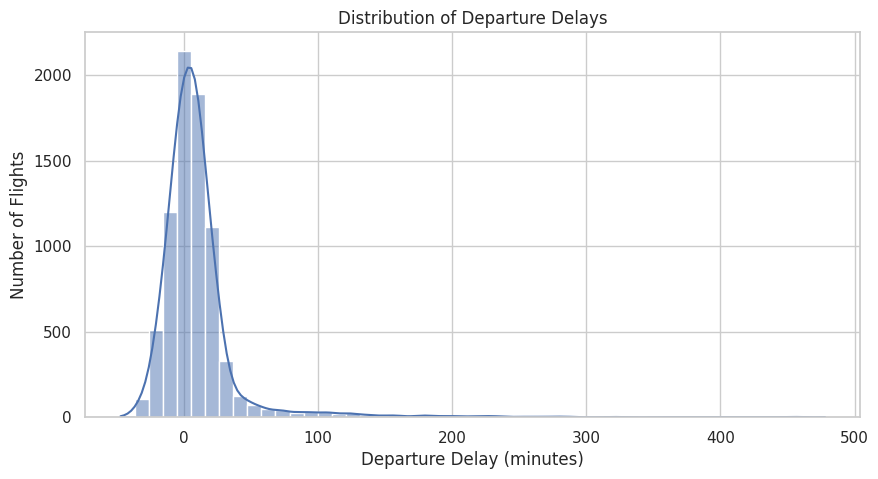

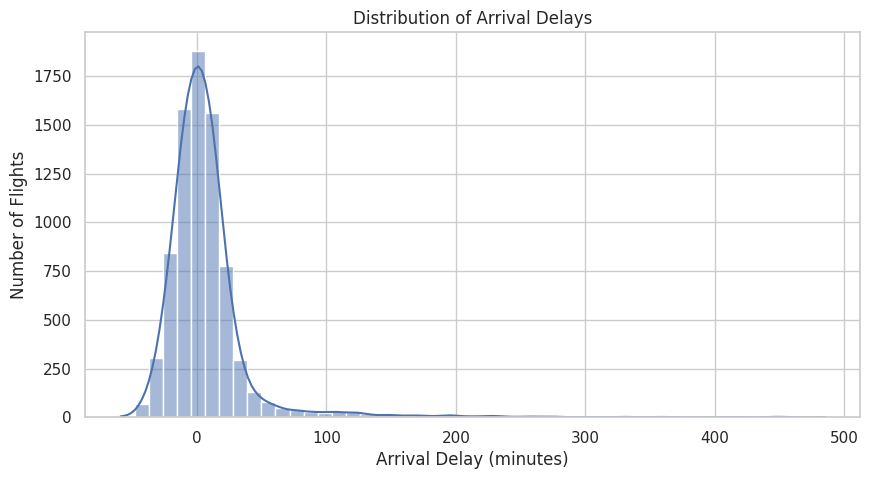

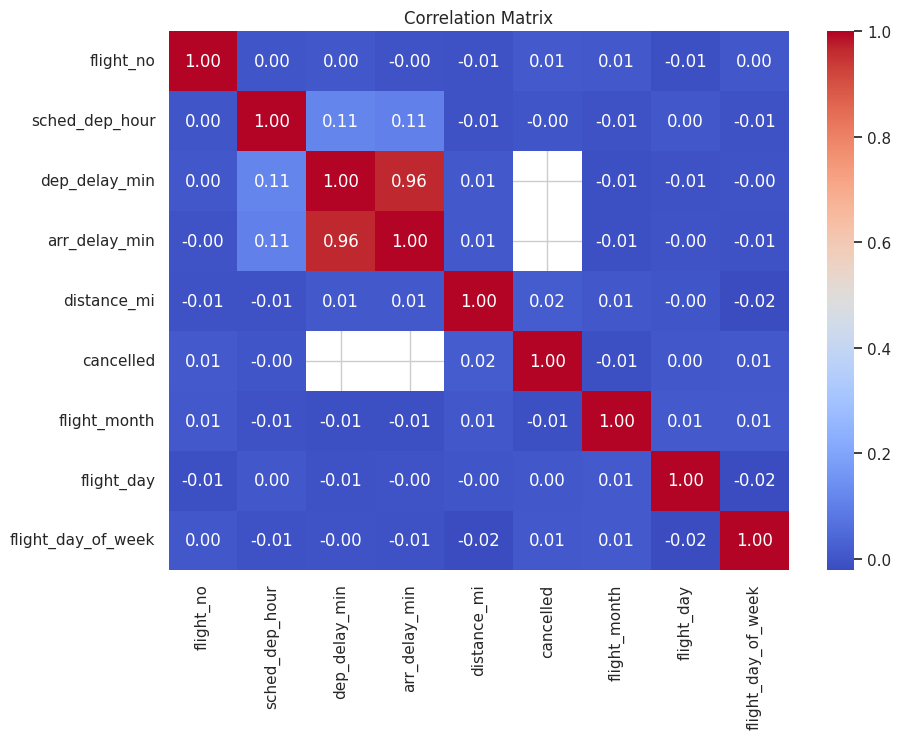

In [ ]:
# Visualize departure delay distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["dep_delay_min"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Departure Delays")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Number of Flights")
plt.show()


# Visualize arrival delay distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["arr_delay_min"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.show()


# Correlation between numerical features
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()





Cell 6 — Define Preprocessing Functions

In [ ]:
def create_preprocessor(numeric_features, categorical_features):
    """
    Create a preprocessing pipeline.

    Numerical features:
    - Fill missing values using the median.
    - Standardize the values.

    Categorical features:
    - Fill missing values using the most frequent value.
    - Apply One-Hot Encoding.
    """

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    return preprocessor

Cell 7 — Regression: Predict Arrival Delay

In [ ]:
# Exclude cancelled flights
regression_df = df_clean[
    df_clean["cancelled"] == 0
].copy()

# Remove rows with missing target values
regression_df = regression_df.dropna(
    subset=["arr_delay_min"]
)

# Define the target variable
y_reg = regression_df["arr_delay_min"]

# Define input features
regression_features = [
    "carrier",
    "origin",
    "dest",
    "sched_dep_hour",
    "dep_delay_min",
    "distance_mi",
    "flight_month",
    "flight_day",
    "flight_day_of_week"
]

X_reg = regression_df[regression_features]

# Identify numerical and categorical features
numeric_features = [
    "sched_dep_hour",
    "dep_delay_min",
    "distance_mi",
    "flight_month",
    "flight_day",
    "flight_day_of_week"
]

categorical_features = [
    "carrier",
    "origin",
    "dest"
]

# Split the data into training and testing sets
X_train_reg, X_test_reg, y_train_reg, y_test_reg = (
    train_test_split(
        X_reg,
        y_reg,
        test_size=0.20,
        random_state=RANDOM_STATE
    )
)

print("Training data:", X_train_reg.shape)
print("Testing data:", X_test_reg.shape)

Training data: (6266, 9)
Testing data: (1567, 9)


Cell 8 — Train the Regression Model

In [ ]:
# Create preprocessing pipeline
regression_preprocessor = create_preprocessor(
    numeric_features,
    categorical_features
)

# Create the complete regression pipeline
regression_model = Pipeline([
    ("preprocessor", regression_preprocessor),
    ("model", LinearRegression())
])

# Train the model
regression_model.fit(
    X_train_reg,
    y_train_reg
)

# Make predictions
y_pred_reg = regression_model.predict(X_test_reg)

print("Regression model trained successfully!")

Regression model trained successfully!


Cell 9 — Evaluate Regression Performance

In [ ]:
# Calculate evaluation metrics
mse = mean_squared_error(
    y_test_reg,
    y_pred_reg
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_reg,
    y_pred_reg
)

# Print results
print("Regression Evaluation Results")
print("-" * 35)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

Regression Evaluation Results
-----------------------------------
Mean Squared Error (MSE): 80.42
Root Mean Squared Error (RMSE): 8.97
R2 Score: 0.9234


Cell 10 — Classification: Create Binary Target

Classification target distribution:
is_delayed
0    5699
1    2134
Name: count, dtype: int64


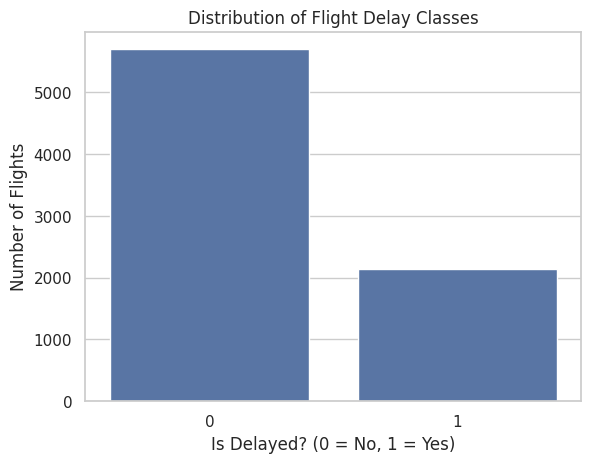

In [ ]:
# Exclude cancelled flights
classification_df = df_clean[
    df_clean["cancelled"] == 0
].copy()

# Remove rows where departure delay is unknown
classification_df = classification_df.dropna(
    subset=["dep_delay_min"]
)

# Create binary target
classification_df["is_delayed"] = (
    classification_df["dep_delay_min"] >= 15
).astype(int)

# Display class distribution
print("Classification target distribution:")
print(
    classification_df["is_delayed"]
    .value_counts()
)

sns.countplot(
    data=classification_df,
    x="is_delayed"
)

plt.title("Distribution of Flight Delay Classes")
plt.xlabel("Is Delayed? (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")
plt.show()

Cell 11 — Prepare Classification Data

In [ ]:
# Define classification target
y_cls = classification_df["is_delayed"]

# Define input features
classification_features = [
    "carrier",
    "origin",
    "dest",
    "sched_dep_hour",
    "distance_mi",
    "flight_month",
    "flight_day",
    "flight_day_of_week"
]

X_cls = classification_df[classification_features]

# Numerical features
numeric_cls = [
    "sched_dep_hour",
    "distance_mi",
    "flight_month",
    "flight_day",
    "flight_day_of_week"
]

# Categorical features
categorical_cls = [
    "carrier",
    "origin",
    "dest"
]

# Split the data using stratification
X_train_cls, X_test_cls, y_train_cls, y_test_cls = (
    train_test_split(
        X_cls,
        y_cls,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y_cls
    )
)

print("Training data:", X_train_cls.shape)
print("Testing data:", X_test_cls.shape)

Training data: (6266, 8)
Testing data: (1567, 8)


In [ ]:
Cell 12 — Train the Classification Model

In [ ]:
# Create preprocessing pipeline
classification_preprocessor = create_preprocessor(
    numeric_cls,
    categorical_cls
)

# Create Logistic Regression pipeline
classification_model = Pipeline([
    ("preprocessor", classification_preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    )
])

# Train the model
classification_model.fit(
    X_train_cls,
    y_train_cls
)

# Predict classes
y_pred_cls = classification_model.predict(X_test_cls)

print("Classification model trained successfully!")

Classification model trained successfully!


Cell 13 — Evaluate Classification Performance

Classification Evaluation Results
----------------------------------------
Accuracy: 0.6082

Classification Report:
              precision    recall  f1-score   support

 Not Delayed       0.81      0.61      0.69      1140
     Delayed       0.37      0.61      0.46       427

    accuracy                           0.61      1567
   macro avg       0.59      0.61      0.58      1567
weighted avg       0.69      0.61      0.63      1567


Confusion Matrix:
[[694 446]
 [168 259]]


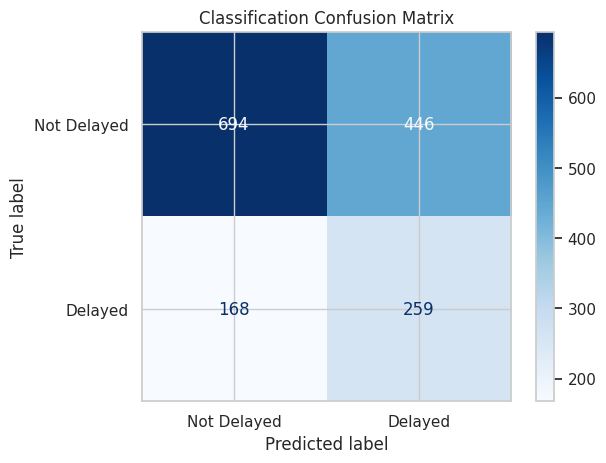

In [ ]:
# Calculate accuracy
accuracy = accuracy_score(
    y_test_cls,
    y_pred_cls
)

print("Classification Evaluation Results")
print("-" * 40)

print(f"Accuracy: {accuracy:.4f}")

# Print classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test_cls,
        y_pred_cls,
        target_names=[
            "Not Delayed",
            "Delayed"
        ],
        zero_division=0
    )
)

# Generate confusion matrix
cm = confusion_matrix(
    y_test_cls,
    y_pred_cls
)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Delayed", "Delayed"]
).plot(cmap="Blues")

plt.title("Classification Confusion Matrix")
plt.show()

Cell 14 — Clustering: Prepare Features

In [ ]:
# Exclude cancelled flights
clustering_df = df_clean[
    df_clean["cancelled"] == 0
].copy()

# Select clustering features
clustering_features = [
    "sched_dep_hour",
    "distance_mi",
    "dep_delay_min"
]

X_cluster = clustering_df[clustering_features].copy()

# Handle missing values and scale features
cluster_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_cluster_scaled = cluster_preprocessor.fit_transform(
    X_cluster
)

print("Clustering data shape:", X_cluster_scaled.shape)

Clustering data shape: (7833, 3)


Cell 15 — Elbow Method

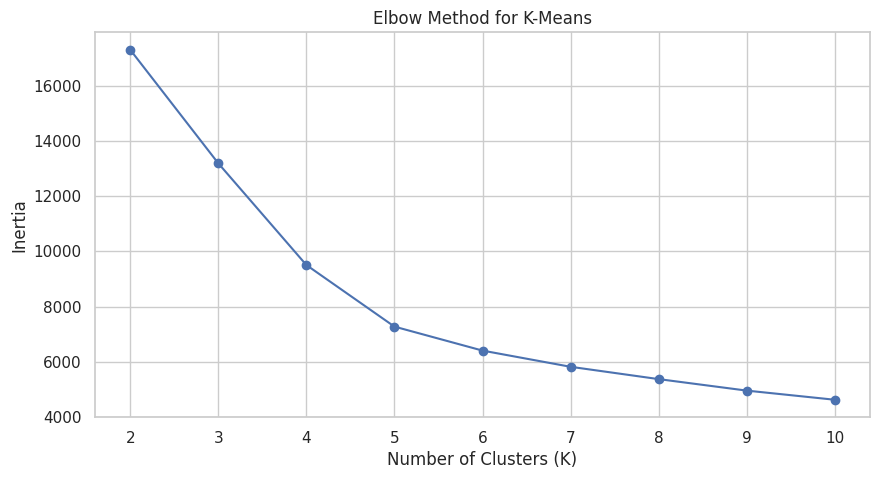

In [ ]:
# Test different values of K
k_values = range(2, 11)

inertia_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    kmeans.fit(X_cluster_scaled)

    inertia_values.append(kmeans.inertia_)

# Plot Elbow curve
plt.figure(figsize=(10, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.show()

Cell 16 — Train Final K-Means Model

In [ ]:
# Change this value after inspecting the Elbow plot
optimal_k = 3

# Train final K-Means model
kmeans_final = KMeans(
    n_clusters=optimal_k,
    random_state=RANDOM_STATE,
    n_init=10
)

# Assign cluster labels
cluster_labels = kmeans_final.fit_predict(
    X_cluster_scaled
)

# Add cluster labels to the dataset
clustering_df["cluster"] = cluster_labels

print("Selected number of clusters:", optimal_k)

print("\nNumber of flights in each cluster:")
print(
    clustering_df["cluster"].value_counts().sort_index()
)

Selected number of clusters: 3

Number of flights in each cluster:
cluster
0    3731
1    3876
2     226
Name: count, dtype: int64


Cell 17 — Evaluate Clustering with Silhouette Score

In [ ]:
# Calculate Silhouette Score
silhouette = silhouette_score(
    X_cluster_scaled,
    cluster_labels
)

print("Clustering Evaluation Results")
print("-" * 35)

print(f"Silhouette Score: {silhouette:.4f}")

Clustering Evaluation Results
-----------------------------------
Silhouette Score: 0.3071


Cell 18 — Visualize Clusters

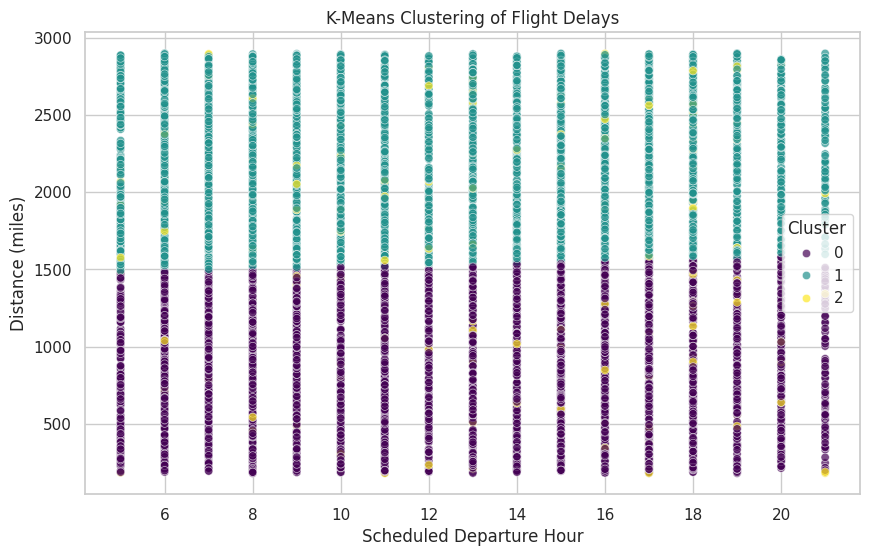

In [ ]:
# Visualize clusters using departure hour and distance
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clustering_df,
    x="sched_dep_hour",
    y="distance_mi",
    hue="cluster",
    palette="viridis",
    alpha=0.7
)

plt.title("K-Means Clustering of Flight Delays")
plt.xlabel("Scheduled Departure Hour")
plt.ylabel("Distance (miles)")
plt.legend(title="Cluster")
plt.show()

Cell 19 — Final Summary

In [ ]:
# Regression summary
print("REGRESSION")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# Classification summary
print("\nCLASSIFICATION")
print("Accuracy:", round(accuracy, 4))

# Clustering summary
print("\nCLUSTERING")
print("Optimal K selected:", optimal_k)
print("Silhouette Score:", round(silhouette, 4))



REGRESSION
MSE: 80.42
RMSE: 8.97
R2 Score: 0.9234

CLASSIFICATION
Accuracy: 0.6082

CLUSTERING
Optimal K selected: 3
Silhouette Score: 0.3071
